**Note.** This notebook reads `data/simulation_19.csv` (190 variables, 400 observations). The outputs below were regenerated by running the two notebooks `Gras_Algorithm.ipynb` and `Optimized_Algorithm.ipynb` in the same environment, so that their running times can be compared; running times depend on the machine.

## Algorithme optimisé

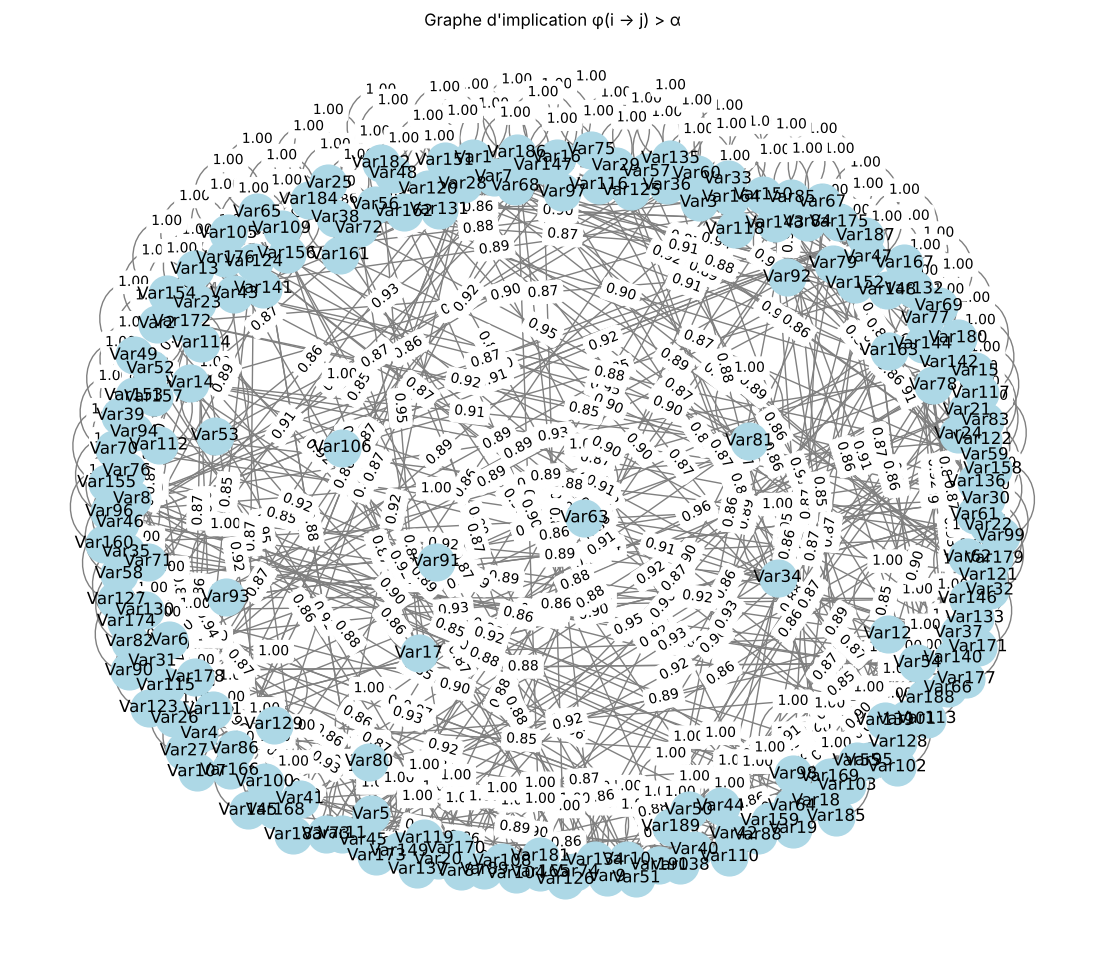

['Var74']
['Var77']
['Var121']
['Var11']
['Var12']
['Var31']
['Var53']
['Var1']
['Var151']
['Var188']
['Var100']
['Var72']
['Var22']
['Var20']
['Var88']
['Var3']
['Var105']
['Var130']
['Var8']
['Var176']
['Var120']
['Var108']
['Var52']
['Var18']
['Var156']
['Var98']
['Var70']
['Var59']
['Var186']
['Var133']
['Var62']
['Var177']
['Var160']
['Var190']
['Var152']
['Var19']
['Var4']
['Var185']
['Var181']
['Var183']
['Var94']
['Var24']
['Var179']
['Var136']
['Var47']
['Var42']
['Var189']
['Var16']
['Var14']
['Var103']
['Var40']
['Var167']
['Var69']
['Var126']
['Var132']
['Var10']
['Var106']
['Var170']
['Var187']
['Var29']
['Var124']
['Var93']
['Var166']
['Var161']
['Var158']
['Var55']
['Var87']
['Var110']
['Var46']
['Var169']
['Var118']
['Var26']
['Var34']
['Var2']
['Var140']
['Var137']
['Var117']
['Var99']
['Var9']
['Var5']
['Var45']
['Var145']
['Var63']
['Var168']
['Var83']
['Var138']
['Var38']
['Var58']
['Var56']
['Var111']
['Var17']
['Var141']
['Var171']
['Var131']
['Var104']
['Var43']


In [1]:
import pandas as pd
import math as mt
import numpy as np
import time
from scipy.stats import poisson
import networkx as nx
import matplotlib.pyplot as plt

# Function to calculate the implication intensity
debut = time.perf_counter()

def intensite_implication(n_x, n_y, n_xy, n):
    lamb = n_x * (n - n_y) / n
    if n_x > n_y:
        return 0
    else:
        phi = 1 - poisson.cdf(n_xy, lamb)
        return phi


# Function to generate the implication matrix x=1 ⇒ y=0
def matrice_implication(fichier_csv):
    #df = pd.read_csv(fichier_csv).astype(int)
    df = pd.read_csv(fichier_csv)
    n = len(df)
    attributs = df.columns
    taille = len(attributs)
    
    matrice = pd.DataFrame(np.zeros((taille, taille)), index=attributs, columns=attributs)

    for i, x in enumerate(attributs):
        for j, y in enumerate(attributs):
            n_x = df[x].sum()
            n_y = df[y].sum()
            n_xy = ((df[x] == 1) & (df[y] == 0)).sum()
            phi = intensite_implication(n_x, n_y, n_xy, n)
            matrice.iloc[i, j] = phi

    return matrice

# Time to build the matrix
mat = matrice_implication("data/simulation_19.csv")

def graphe(matrice, alpha):
    """
    Constructs and displays the directed graph of implications where
    i → j if matrice.loc[i, j] > alpha
    """
    # Creation of the directed graph
    G = nx.DiGraph()

    # Add the edges according to the matrix
    for i in matrice.index:
        for j in matrice.columns:
            if matrice.loc[i, j] > alpha:
                G.add_edge(i, j, weight=matrice.loc[i, j])

    # Graph layout (automatic layout)
    pos = nx.spring_layout(G, seed=42)  # node positioning

    # Drawing nodes and edges
    pos = nx.spring_layout(G, seed=42, k=1.5)  # k = repulsion factor between nodes
    plt.figure(figsize=(14, 12))              # increases the size of the figure

    #plt.figure(figsize=(10, 8))
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=700)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True)
    nx.draw_networkx_labels(G, pos, font_size=12, font_family='sans-serif')

    # Add weights (values of φ) to the edges if you want.
    edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10)

    plt.title("Graphe d'implication φ(i → j) > α")
    plt.axis('off')
    plt.show()

    return G  # You can use this graph for other processes

alpha = 0.85
G = graphe(mat, alpha)

def consequent(G):
    """
    Given a directed graph G, returns a dictionary of the attributes involved
    by each vertex i (by transitivity).
    """
    resultats = {}
    for i in G.nodes:
        # Nodes reachable from i (not including i itself)
        atteints = nx.descendants(G, i)
        resultats[i] = sorted(atteints)
        resultats[i].append(i)
    return resultats

import networkx as nx

def premisse(G):
    """
    For each vertex i, return the vertices x such that x → i (transitively).
    """
    G_transpose = G.reverse(copy=True)  # reverses all edges
    resultats = {}
    for i in G.nodes:
        antécédents = nx.descendants(G_transpose, i)
        resultats[i] = sorted(antécédents)
        resultats[i].append(i)
    return resultats
    
#G = graphe(mat, alpha)
def treillis(G):
    conséquents = consequent(G)
    antécédents = premisse(G)
    list_antécédents = list(antécédents.values())
    list_conséquents = list(conséquents.values())
    concatenate= (list_antécédents + list_conséquents)
    for x in G.nodes:
        concatenate.append([x])  # singleton class {x}
    #T = consequent(matrice, alpha)
    #for clas in premisse(matrice, alpha):
        #T.add(clas)
    return concatenate

def tri_topologique(resultats):
    from copy import deepcopy

    E_arcs = []
    resultats = [tuple(sorted(C)) for C in resultats]  # Tuples sorted to standardize
    resultats = list(set(resultats))  # Remove duplicates
    in_degre = {C: 0 for C in resultats}

    # Construction of arcs according to strict inclusion
    for Ci in resultats:
        for Cj in resultats:
            if Ci != Cj and set(Ci).issubset(set(Cj)) and len(Ci) < len(Cj):
                E_arcs.append((Ci, Cj))
                in_degre[Cj] += 1

    S = sorted([C for C in resultats if in_degre[C] == 0], key=len)
    L = []

    while S:
        Ci = S.pop(0)
        L.append(Ci)
        for arc in E_arcs[:]:
            if arc[0] == Ci:
                Cj = arc[1]
                E_arcs.remove(arc)
                in_degre[Cj] -= 1
                if in_degre[Cj] == 0:
                    S.append(Cj)
        S = sorted(S, key=len)

    return [list(C) for C in L]
T = treillis(G)
heriarchi = tri_topologique(T)

def hierarchie_orientee(resultats):
    # Copy the sorted list
    l = resultats
    retire = []
    for Ci in l:
        for Cj in l:
            if len(Ci)<len(Cj) and set(Ci)&set(Cj)!=set() and set(Ci)&set(Cj)!=set(Ci):
                retire.append(Cj)
    l = [classe for classe in l if classe not in retire]
    return l
#print("nous avons:", len(hierarchie_orientee(heriarchi)), "classes")
for i in hierarchie_orientee(heriarchi):
   print(i)
fin = time.perf_counter()
t = fin - debut
print(t)